objectif :
Comparer plusieurs modèles
et mesurer l'effet des variables filtrées

# 06 - Model Comparison

Objectif :

Comparer plusieurs modèles et observer l'impact de la sélection des variables.

Deux jeux de données seront testés :

Dataset A :

- Toutes les variables

Dataset B :

- Variables filtrées après EDA

L'objectif est de vérifier si la réduction des variables améliore :

- les performances
- la robustesse
- l'interprétabilité

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report, accuracy_score, f1_score

In [13]:
FINAL_PATH = Path("../data/final")

df = pd.read_csv(FINAL_PATH / "BTCUSD_model_base.csv")

df["date"] = pd.to_datetime(df["date"])

print(df.shape)

(4975, 30)


In [14]:
# Nettoyage avant séparation X / y
df_model = df.dropna().reset_index(drop=True)

X_A = df_model.drop(
    columns=[
        "target",
        "future_return_5",
        "date",
        "symbol"
    ],
    errors="ignore"
)

y = df_model["target"]

In [15]:
variables_to_remove = [
    "open",
    "high",
    "low",
    "change",
    "BB_middle"
]

X_B = X_A.drop(
    columns=variables_to_remove,
    errors="ignore"
)

In [16]:
split = int(len(df) * 0.8)

X_train_A = X_A.iloc[:split]
X_test_A = X_A.iloc[split:]

X_train_B = X_B.iloc[:split]
X_test_B = X_B.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [17]:
print(X_train_A.shape, y_train.shape)
print(X_test_A.shape, y_test.shape)
print(X_train_B.shape, y_train.shape)
print(X_test_B.shape, y_test.shape)

(3980, 26) (3980,)
(995, 26) (995,)
(3980, 21) (3980,)
(995, 21) (995,)


In [18]:
scaler_A = StandardScaler()

X_train_A_scaled = scaler_A.fit_transform(X_train_A)

X_test_A_scaled = scaler_A.transform(X_test_A)


scaler_B = StandardScaler()

X_train_B_scaled = scaler_B.fit_transform(X_train_B)

X_test_B_scaled = scaler_B.transform(X_test_B)

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),

    "LogisticRegression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "GradientBoosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [20]:
results = []

for dataset_name, X_train_scaled, X_test_scaled in [
    ("Dataset A - Toutes variables", X_train_A_scaled, X_test_A_scaled),
    ("Dataset B - Variables filtrées", X_train_B_scaled, X_test_B_scaled)
]:

    print("\n" + "="*80)
    print(dataset_name)
    print("="*80)

    for model_name, model in models.items():

        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_test_scaled)

        report = classification_report(
            y_test,
            y_pred,
            output_dict=True,
            zero_division=0
        )

        results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": report["accuracy"],
            "Precision_BUY": report["1"]["precision"],
            "Recall_BUY": report["1"]["recall"],
            "F1_BUY": report["1"]["f1-score"],
            "Precision_SELL": report["-1"]["precision"],
            "Recall_SELL": report["-1"]["recall"],
            "F1_SELL": report["-1"]["f1-score"],
            "F1_macro": report["macro avg"]["f1-score"]
        })

        print(f"\n--- {model_name} ---")
        print(
            classification_report(
                y_test,
                y_pred,
                zero_division=0
            )
        )


Dataset A - Toutes variables

--- RandomForest ---
              precision    recall  f1-score   support

          -1       0.29      0.72      0.41       260
           0       0.51      0.27      0.36       416
           1       0.35      0.14      0.20       319

    accuracy                           0.35       995
   macro avg       0.38      0.38      0.32       995
weighted avg       0.40      0.35      0.32       995


--- LogisticRegression ---
              precision    recall  f1-score   support

          -1       0.26      0.96      0.41       260
           0       0.44      0.01      0.02       416
           1       0.21      0.02      0.04       319

    accuracy                           0.26       995
   macro avg       0.30      0.33      0.16       995
weighted avg       0.32      0.26      0.13       995


--- GradientBoosting ---
              precision    recall  f1-score   support

          -1       0.27      0.56      0.36       260
           0       0.48

In [21]:
results_df = pd.DataFrame(results)

results_df

,Dataset,Model,Accuracy,Precision_BUY,Recall_BUY,F1_BUY,Precision_SELL,Recall_SELL,F1_SELL,F1_macro
0,Dataset A - Toutes variables,RandomForest,0.346734,0.352000,0.137931,0.198198,0.289231,0.723077,0.413187,0.322244
1,Dataset A - Toutes variables,LogisticRegression,0.261307,0.205882,0.021944,0.039660,0.261555,0.957692,0.410891,0.156458
2,Dataset A - Toutes variables,GradientBoosting,0.319598,0.302682,0.247649,0.272414,0.269871,0.561538,0.364544,0.314126
3,Dataset B - Variables filtrées,RandomForest,0.343719,0.347518,0.153605,0.213043,0.285266,0.700000,0.405345,0.323218
4,Dataset B - Variables filtrées,LogisticRegression,0.259296,0.228571,0.025078,0.045198,0.260960,0.961538,0.410509,0.151902
5,Dataset B - Variables filtrées,GradientBoosting,0.335678,0.321555,0.285266,0.302326,0.265659,0.473077,0.340249,0.334492


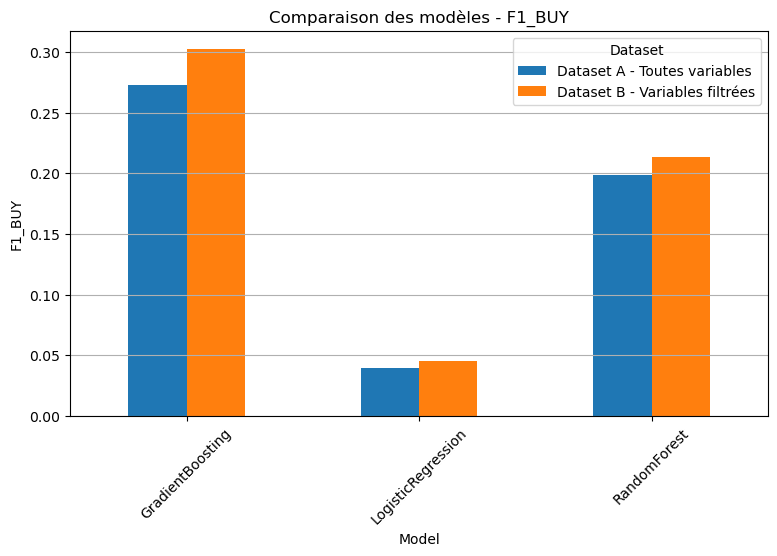

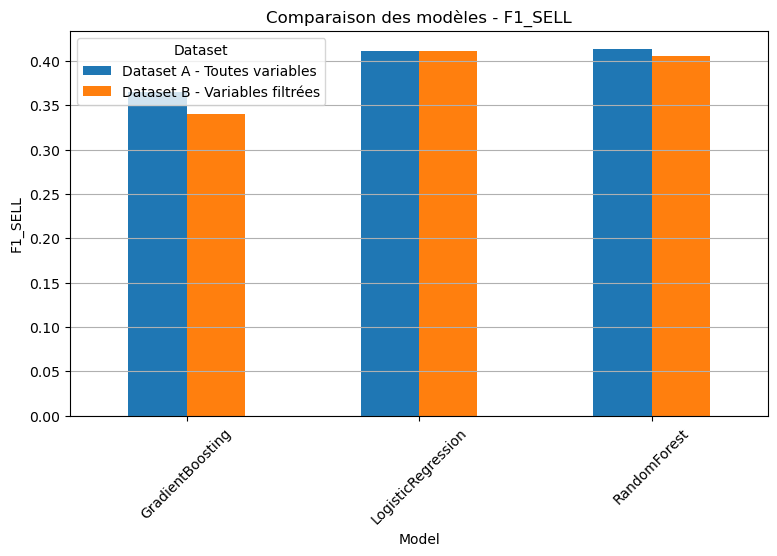

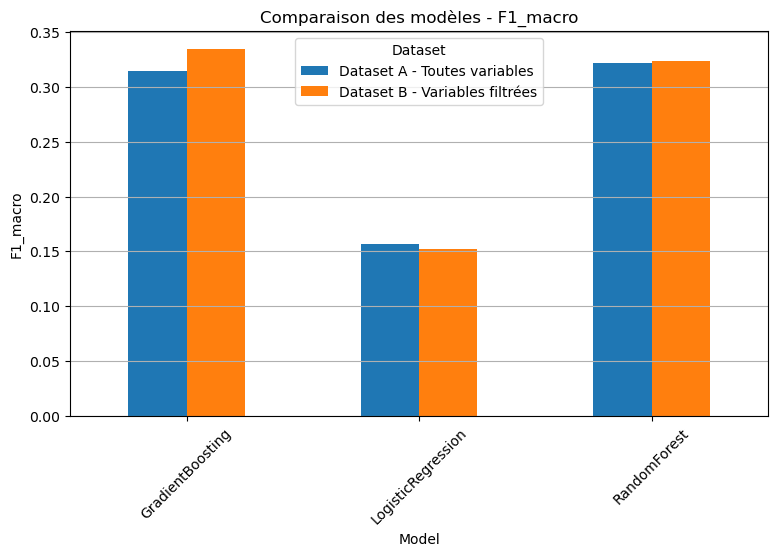

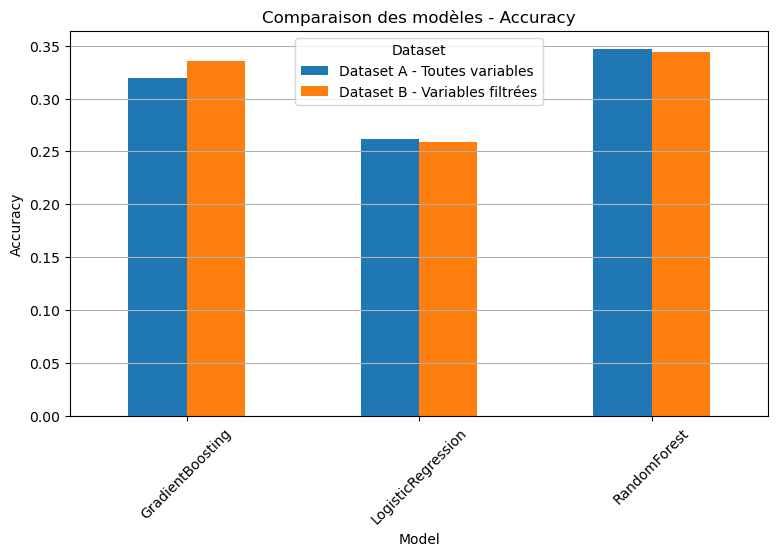

In [22]:
metrics = [
    "F1_BUY",
    "F1_SELL",
    "F1_macro",
    "Accuracy"
]

for metric in metrics:

    pivot = results_df.pivot(
        index="Model",
        columns="Dataset",
        values=metric
    )

    pivot.plot(
        kind="bar",
        figsize=(9,5)
    )

    plt.title(f"Comparaison des modèles - {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.show()


Les modèles basés sur les arbres semblent mieux adaptés au comportement non linéaire du marché BTC que la régression logistique.

Le filtrage des variables semble apporter une légère amélioration des performances sur plusieurs métriques.

GradientBoosting obtient les meilleurs résultats sur le signal BUY ainsi que sur le F1-score global.

RandomForest présente une meilleure accuracy mais cette métrique seule n'est pas suffisante pour évaluer la qualité des signaux de trading.

La suite de l'étude sera réalisée avec les modèles RandomForest et GradientBoosting.

In [23]:
# Nous allons tester d'autres variables à supprimer

# X_B = X_A sans open, high, low, change, BB_middle

extra_variables_to_test = [
    "vwap",
    "BB_upper",
    "BB_lower"
]

X_C = X_B.drop(
    columns=extra_variables_to_test,
    errors="ignore"
)

In [24]:
split = int(len(df_model) * 0.8)

X_train_B = X_B.iloc[:split]
X_test_B = X_B.iloc[split:]

X_train_C = X_C.iloc[:split]
X_test_C = X_C.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [25]:
scaler_B = StandardScaler()
X_train_B_scaled = scaler_B.fit_transform(X_train_B)
X_test_B_scaled = scaler_B.transform(X_test_B)

scaler_C = StandardScaler()
X_train_C_scaled = scaler_C.fit_transform(X_train_C)
X_test_C_scaled = scaler_C.transform(X_test_C)

In [26]:
models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),

    "GradientBoosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [27]:
results_final_dataset = []

datasets = {
    "Dataset B - filtré": (X_train_B_scaled, X_test_B_scaled),
    "Dataset C - filtré avancé": (X_train_C_scaled, X_test_C_scaled)
}

for dataset_name, (X_train_scaled, X_test_scaled) in datasets.items():

    print("\n" + "="*80)
    print(dataset_name)
    print("="*80)

    for model_name, model in models.items():

        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_test_scaled)

        report = classification_report(
            y_test,
            y_pred,
            output_dict=True,
            zero_division=0
        )

        results_final_dataset.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": report["accuracy"],
            "F1_BUY": report["1"]["f1-score"],
            "F1_SELL": report["-1"]["f1-score"],
            "F1_macro": report["macro avg"]["f1-score"]
        })

        print(f"\n--- {model_name} ---")
        print(classification_report(y_test, y_pred, zero_division=0))


Dataset B - filtré

--- RandomForest ---
              precision    recall  f1-score   support

          -1       0.29      0.70      0.41       260
           0       0.51      0.27      0.35       416
           1       0.35      0.15      0.21       319

    accuracy                           0.34       995
   macro avg       0.38      0.37      0.32       995
weighted avg       0.40      0.34      0.32       995


--- GradientBoosting ---
              precision    recall  f1-score   support

          -1       0.27      0.47      0.34       260
           0       0.48      0.29      0.36       416
           1       0.32      0.29      0.30       319

    accuracy                           0.34       995
   macro avg       0.36      0.35      0.33       995
weighted avg       0.37      0.34      0.34       995


Dataset C - filtré avancé

--- RandomForest ---
              precision    recall  f1-score   support

          -1       0.29      0.72      0.42       260
           0

In [28]:
results_final_dataset_df = pd.DataFrame(results_final_dataset)

results_final_dataset_df.sort_values(
    by="F1_BUY",
    ascending=False
)

,Dataset,Model,Accuracy,F1_BUY,F1_SELL,F1_macro
1,Dataset B - filtré,GradientBoosting,0.335678,0.302326,0.340249,0.334492
2,Dataset C - filtré avancé,RandomForest,0.338693,0.213220,0.415094,0.316965
0,Dataset B - filtré,RandomForest,0.343719,0.213043,0.405345,0.323218
3,Dataset C - filtré avancé,GradientBoosting,0.316583,0.195556,0.393235,0.291662


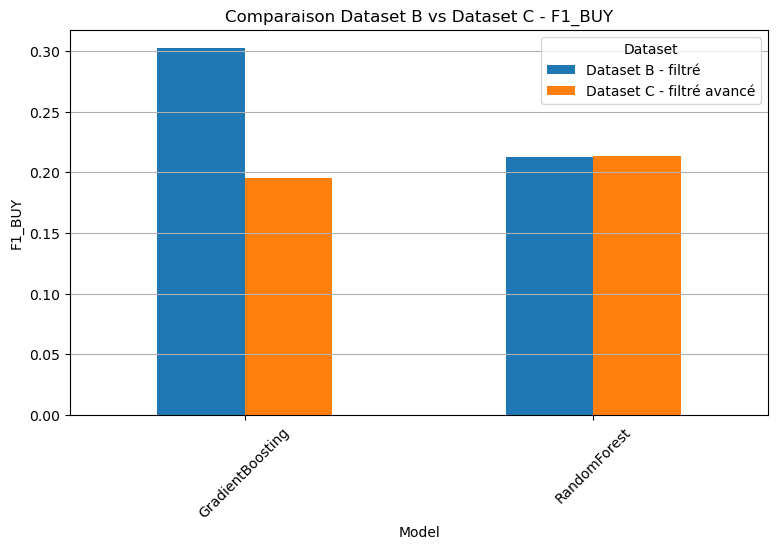

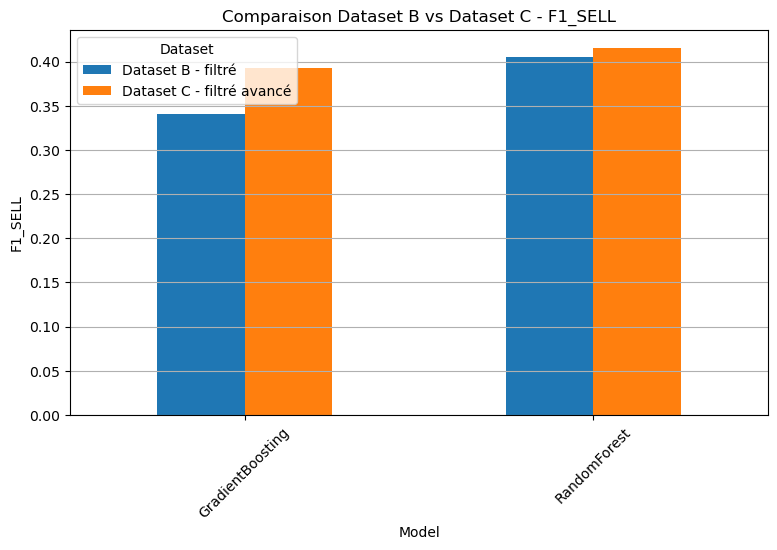

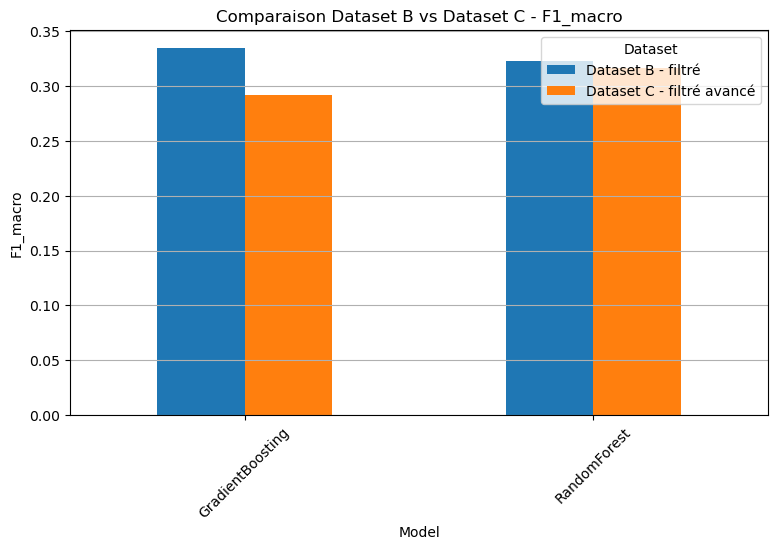

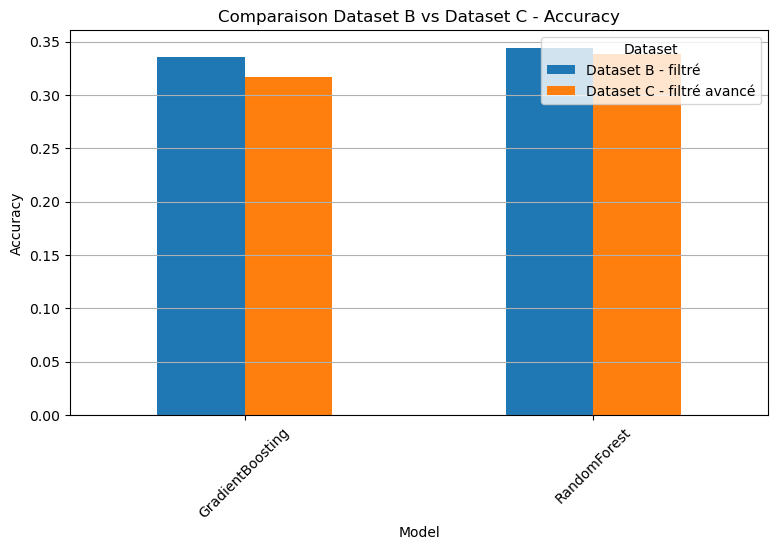

In [29]:
metrics = [
    "F1_BUY",
    "F1_SELL",
    "F1_macro",
    "Accuracy"
]

for metric in metrics:

    pivot = results_final_dataset_df.pivot(
        index="Model",
        columns="Dataset",
        values=metric
    )

    pivot.plot(
        kind="bar",
        figsize=(9,5)
    )

    plt.title(f"Comparaison Dataset B vs Dataset C - {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.show()



Une étape supplémentaire a été réalisée afin d'évaluer l'impact de variables potentiellement redondantes :

- vwap
- BB_upper
- BB_lower

Malgré leur forte corrélation avec d'autres variables, leur suppression entraîne une baisse des performances sur plusieurs métriques, notamment F1_BUY et Accuracy.

Ces variables apportent donc une information complémentaire au modèle.

Le Dataset B est retenu comme dataset final pour la suite du projet.

In [30]:
X_final = X_B.copy()

final_features = X_B.columns.tolist()

In [31]:
print(final_features)

['close', 'volume', 'changePercent', 'vwap', 'return', 'return_1', 'return_3', 'return_7', 'volatility_5', 'volatility_20', 'sma_20', 'ema_20', 'dist_sma', 'dist_ema', 'rsi', 'BB_upper', 'BB_lower', 'BB_width', 'BB_percent', 'trend_signal', 'return_acceleration']


In [32]:
df_final = df_model[
    final_features + ["target"]
]

df_final.to_csv(
    "../data/final/BTCUSD_final_dataset.csv",
    index=False
)

print("Dataset final sauvegardé")

Dataset final sauvegardé
